In [1]:
# Imports
import os
from pathlib import Path
from osgeo import gdal, ogr
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import geopandas as gpd
import rasterio
from rasterio.plot import show
from concurrent.futures import ThreadPoolExecutor

# Enable GDAL exceptions
gdal.UseExceptions()

print("✅ Imports successful")

✅ Imports successful


In [2]:
# --- SITE 1: Supersite DD0001 [MEDIUM] ---
# input_raster_path = '/home/laura/Documents/uas_data/Calperum/site1_supersite_DD0001/orthomosaic/20220519_SASMDD0001_dual_ortho_05.tif'
# grid_shapefile_path = '/media/laura/Extreme SSD/qgis/calperumResearch/site1_1_DD0001/inputs/masks/tiles_3072/raw/pv_class/annotations/griding/grid_annotation_3072.shp'
# output_raster_folder = '/media/laura/laura_usb/qgis/calperumResearch/site1_1_DD0001/inputs/predictors/tiles_3072/raw'

# --- SITE 2: Vegetation DD0011 [LOW] ---
input_raster_path = '/data/calperumResearch/site2_1_DD0011/imagery/20220517_SASMDD0011_dual_ortho_06.tif'
grid_shapefile_path = '/data/calperumResearch/site2_1_DD0011/imagery/inputs/predictors/tiles_3072/gridding/grid_annotation_3072.shp'
output_raster_folder = '/data/calperumResearch/site2_1_DD0011/imagery/inputs/predictors/tiles_3072/raw'

# Grid filtering parameters
grid_id_field = "id"  # Replace with your grid ID field name
annotated_field = "annotated"  # The name of the field used for filtering
annotated_value = 1  # The value in the 'annotated' field used for filtering

print("--- Configuration ---")
print(f"Input raster: {input_raster_path}")
print(f"Grid shapefile: {grid_shapefile_path}")
print(f"Output folder: {output_raster_folder}")
print(f"Filter: {annotated_field} = {annotated_value}")
print("---------------------")

--- Configuration ---
Input raster: /data/calperumResearch/site2_1_DD0011/imagery/20220517_SASMDD0011_dual_ortho_06.tif
Grid shapefile: /data/calperumResearch/site2_1_DD0011/imagery/inputs/predictors/tiles_3072/gridding/grid_annotation_3072.shp
Output folder: /data/calperumResearch/site2_1_DD0011/imagery/inputs/predictors/tiles_3072/raw
Filter: annotated = 1
---------------------


In [4]:
# Check if files exist
if os.path.exists(input_raster_path):
    print(f"✅ Raster found: {os.path.basename(input_raster_path)}")
    
    # Get raster info
    with rasterio.open(input_raster_path) as src:
        print(f"   Bands: {src.count}")
        print(f"   Size: {src.width} x {src.height} pixels")
        print(f"   CRS: {src.crs}")
        print(f"   Bounds: {src.bounds}")
        print(f"   Resolution: {src.res[0]:.4f} m/pixel")
else:
    print(f"❌ Raster not found: {input_raster_path}")

if os.path.exists(grid_shapefile_path):
    print(f"\n✅ Grid shapefile found: {os.path.basename(grid_shapefile_path)}")
    
    # Get grid info
    grid = gpd.read_file(grid_shapefile_path)
    print(f"   Total grid cells: {len(grid)}")
    print(f"   CRS: {grid.crs}")
    
    # Count annotated cells
    if annotated_field in grid.columns:
        annotated_count = (grid[annotated_field] == annotated_value).sum()
        print(f"   Annotated cells ({annotated_field}={annotated_value}): {annotated_count}")
    else:
        print(f"   ⚠️ Field '{annotated_field}' not found in shapefile")
else:
    print(f"❌ Grid shapefile not found: {grid_shapefile_path}")

✅ Raster found: 20220517_SASMDD0011_dual_ortho_06.tif
   Bands: 10
   Size: 4577 x 5483 pixels
   CRS: EPSG:7854
   Bounds: BoundingBox(left=473069.7393965874, bottom=6235596.731101389, right=473344.3593965874, top=6235925.7111013895)
   Resolution: 0.0600 m/pixel

✅ Grid shapefile found: grid_annotation_3072.shp
   Total grid cells: 99
   CRS: EPSG:7854
   Annotated cells (annotated=1): 18


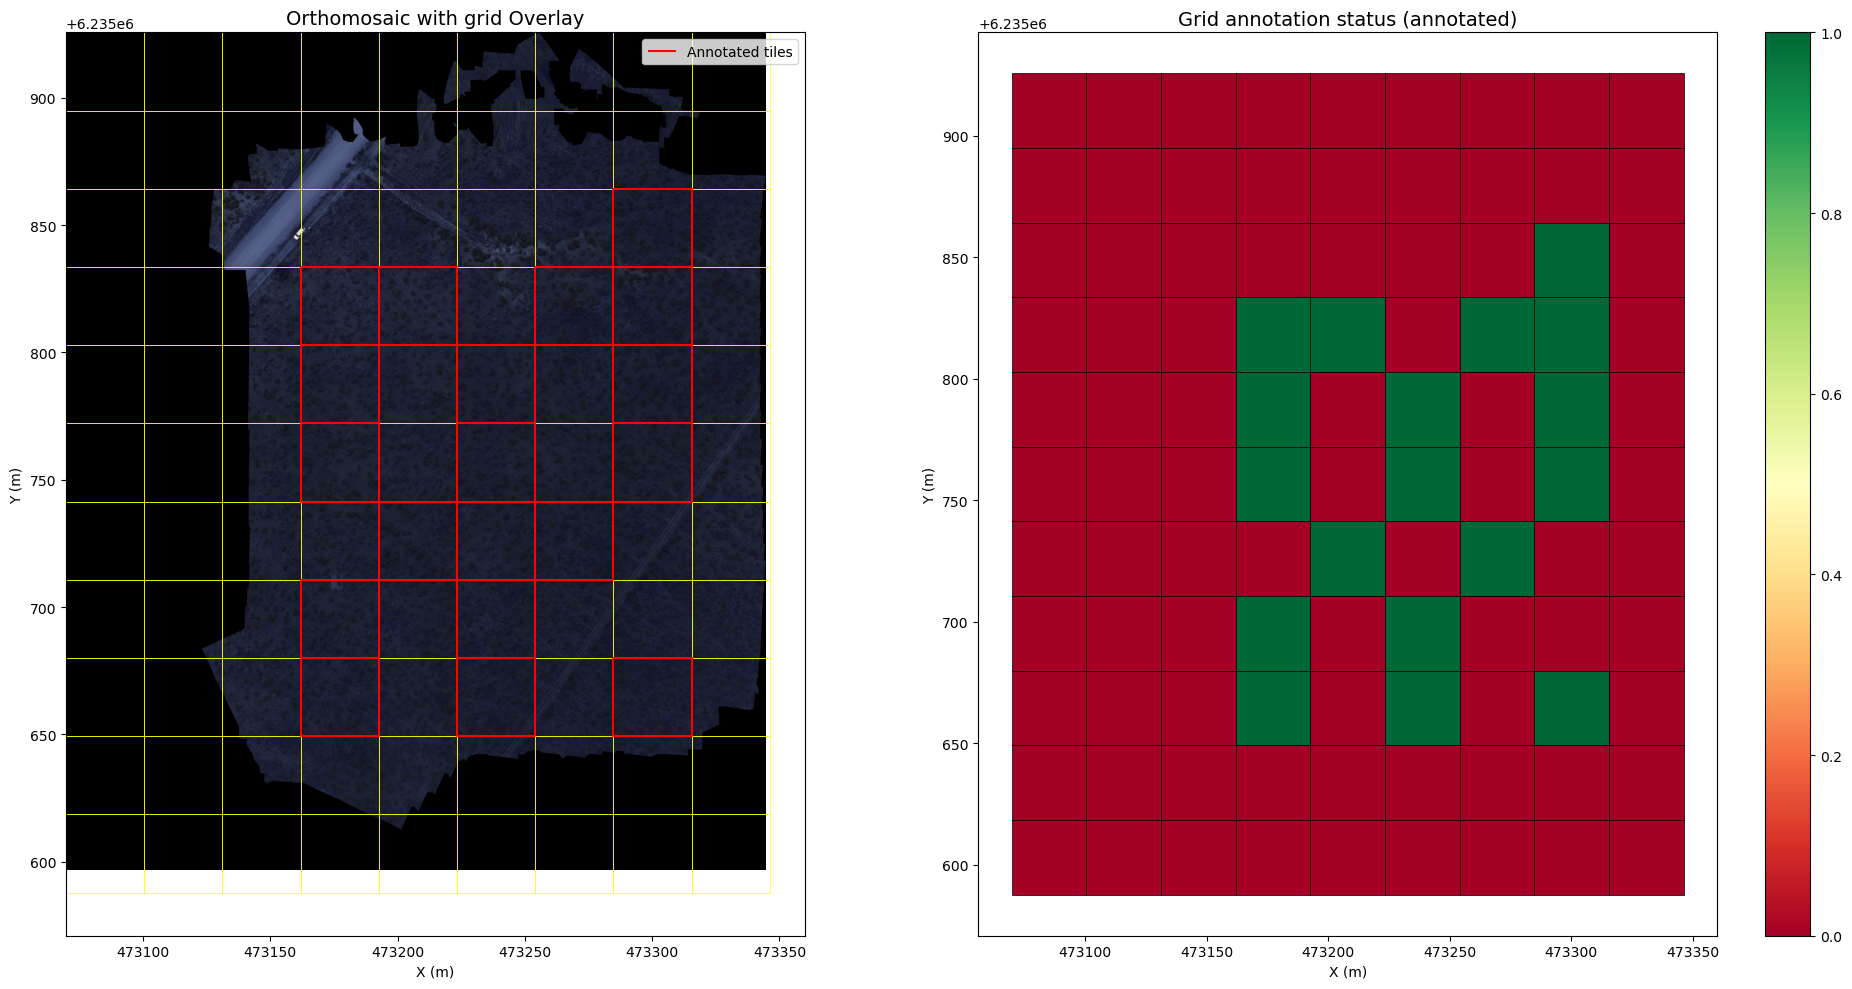


📊 Red outlines show the 18 tiles that will be clipped


In [11]:
# Visualize the orthomosaic and grid overlay
if os.path.exists(input_raster_path) and os.path.exists(grid_shapefile_path):
    fig, axes = plt.subplots(1, 2, figsize=(20, 10))
    
    # Plot 1: Orthomosaic with grid overlay
    with rasterio.open(input_raster_path) as src:
        # Use RGB bands if available (adjust indices for your data)
        if src.count >= 3:
            rgb = np.dstack([src.read(i) for i in [1, 2, 3]])  # R, G, B
            # Normalize for display
            rgb = np.clip(rgb / rgb.max(), 0, 1)
            axes[0].imshow(rgb, extent=[src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top])
        else:
            show(src, ax=axes[0], cmap='gray')
    
    # Overlay grid
    grid.boundary.plot(ax=axes[0], color='yellow', linewidth=0.5)
    if annotated_field in grid.columns:
        annotated_grid = grid[grid[annotated_field] == annotated_value]
        annotated_grid.boundary.plot(ax=axes[0], color='red', linewidth=1.5, label='Annotated tiles')
    
    axes[0].set_title('Orthomosaic with grid Overlay', fontsize=14)
    axes[0].set_xlabel('X (m)')
    axes[0].set_ylabel('Y (m)')
    axes[0].legend()
    
    # Plot 2: Grid cells colored by annotation status
    if annotated_field in grid.columns:
        grid.plot(column=annotated_field, ax=axes[1], cmap='RdYlGn', edgecolor='black', linewidth=0.5, legend=True)
        axes[1].set_title(f'Grid annotation status ({annotated_field})', fontsize=14)
    else:
        grid.plot(ax=axes[1], facecolor='lightblue', edgecolor='black', linewidth=0.5)
        axes[1].set_title('All Grid Cells', fontsize=14)
    
    axes[1].set_xlabel('X (m)')
    axes[1].set_ylabel('Y (m)')
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n📊 Red outlines show the {annotated_count} tiles that will be clipped")
else:
    print("⚠️ Cannot visualize - files not found")

In [6]:
def clip_raster_feature(input_raster_path, grid_feature, output_path):
    src_ds = gdal.Open(input_raster_path)
    if src_ds is None:
        raise RuntimeError("Unable to open input raster.")

    # Fetch the geometry of the grid feature and its envelope
    geom = grid_feature.GetGeometryRef()
    minX, maxX, minY, maxY = geom.GetEnvelope()

    # Define translation options for clipping
    translate_options = gdal.TranslateOptions(format="GTiff", outputType=gdal.GDT_Float32, projWin=[minX, maxY, maxX, minY])

    # Perform the clip and save the output
    gdal.Translate(output_path, src_ds, options=translate_options)


def clip_raster_by_annotated_grid(input_raster_path, grid_shp_path, output_raster_folder, grid_id_field, annotated_field, annotated_value):
    # Ensure the output folder exists
    if not os.path.exists(output_raster_folder):
        os.makedirs(output_raster_folder)

    # Open the grid shapefile and raster
    grid_ds = ogr.Open(grid_shp_path)
    raster_ds = gdal.Open(input_raster_path)

    if not grid_ds or not raster_ds:
        raise ValueError("Could not open the files.")

    grid_layer = grid_ds.GetLayer()

    # Apply attribute filter to select grid features with specified 'annotated' value
    grid_layer.SetAttributeFilter(f"{annotated_field} = {annotated_value}")

    # Loop through each filtered grid feature
    for grid_feature in grid_layer:
        # Get the ID of the current grid feature
        grid_id = grid_feature.GetField(grid_id_field)

        # Prepare the output raster path
        output_raster_path = os.path.join(output_raster_folder, f"tiles_multispectral.{grid_id}.tif")

        # Clip raster
        clip_raster_feature(input_raster_path, grid_feature, output_raster_path)

    print("Raster clipping completed.")

print("✅ Functions defined")

✅ Functions defined


In [7]:
# Run the clipping process
if os.path.exists(input_raster_path) and os.path.exists(grid_shapefile_path):
    num_tiles = clip_raster_by_annotated_grid(
        input_raster_path, 
        grid_shapefile_path, 
        output_raster_folder, 
        grid_id_field, 
        annotated_field, 
        annotated_value
    )
else:
    print("❌ Cannot run clipping - input files not found")
    num_tiles = 0

Raster clipping completed.


Found 18 output tiles

Tile 1 (tiles_multispectral.25.tif):
  Data type: float32
  NoData value: -32767.0
  Total pixels: 262144
  Valid pixels: 262144
  Band 10 stretch: P2=0.170016, P98=0.417848
  Band 6 stretch: P2=0.067412, P98=0.225762
  Band 2 stretch: P2=0.034271, P98=0.072900

Tile 2 (tiles_multispectral.30.tif):
  Data type: float32
  NoData value: -32767.0
  Total pixels: 262144
  Valid pixels: 262144
  Band 10 stretch: P2=0.188930, P98=0.458638
  Band 6 stretch: P2=0.073289, P98=0.251879
  Band 2 stretch: P2=0.039749, P98=0.092104

Tile 3 (tiles_multispectral.31.tif):
  Data type: float32
  NoData value: -32767.0
  Total pixels: 262144
  Valid pixels: 262144
  Band 10 stretch: P2=0.181083, P98=0.425226
  Band 6 stretch: P2=0.073235, P98=0.259351
  Band 2 stretch: P2=0.039671, P98=0.086315

Tile 4 (tiles_multispectral.33.tif):
  Data type: float32
  NoData value: -32767.0
  Total pixels: 262144
  Valid pixels: 262144
  Band 10 stretch: P2=0.162814, P98=0.447511


  Band 6 stretch: P2=0.064893, P98=0.242822
  Band 2 stretch: P2=0.034698, P98=0.080437

Tile 5 (tiles_multispectral.34.tif):
  Data type: float32
  NoData value: -32767.0
  Total pixels: 262144
  Valid pixels: 262144
  Band 10 stretch: P2=0.162435, P98=0.435181
  Band 6 stretch: P2=0.063545, P98=0.238153
  Band 2 stretch: P2=0.034067, P98=0.080369

Tile 6 (tiles_multispectral.39.tif):
  Data type: float32
  NoData value: -32767.0
  Total pixels: 262144
  Valid pixels: 262144
  Band 10 stretch: P2=0.172214, P98=0.421443
  Band 6 stretch: P2=0.071961, P98=0.240966
  Band 2 stretch: P2=0.037814, P98=0.079413



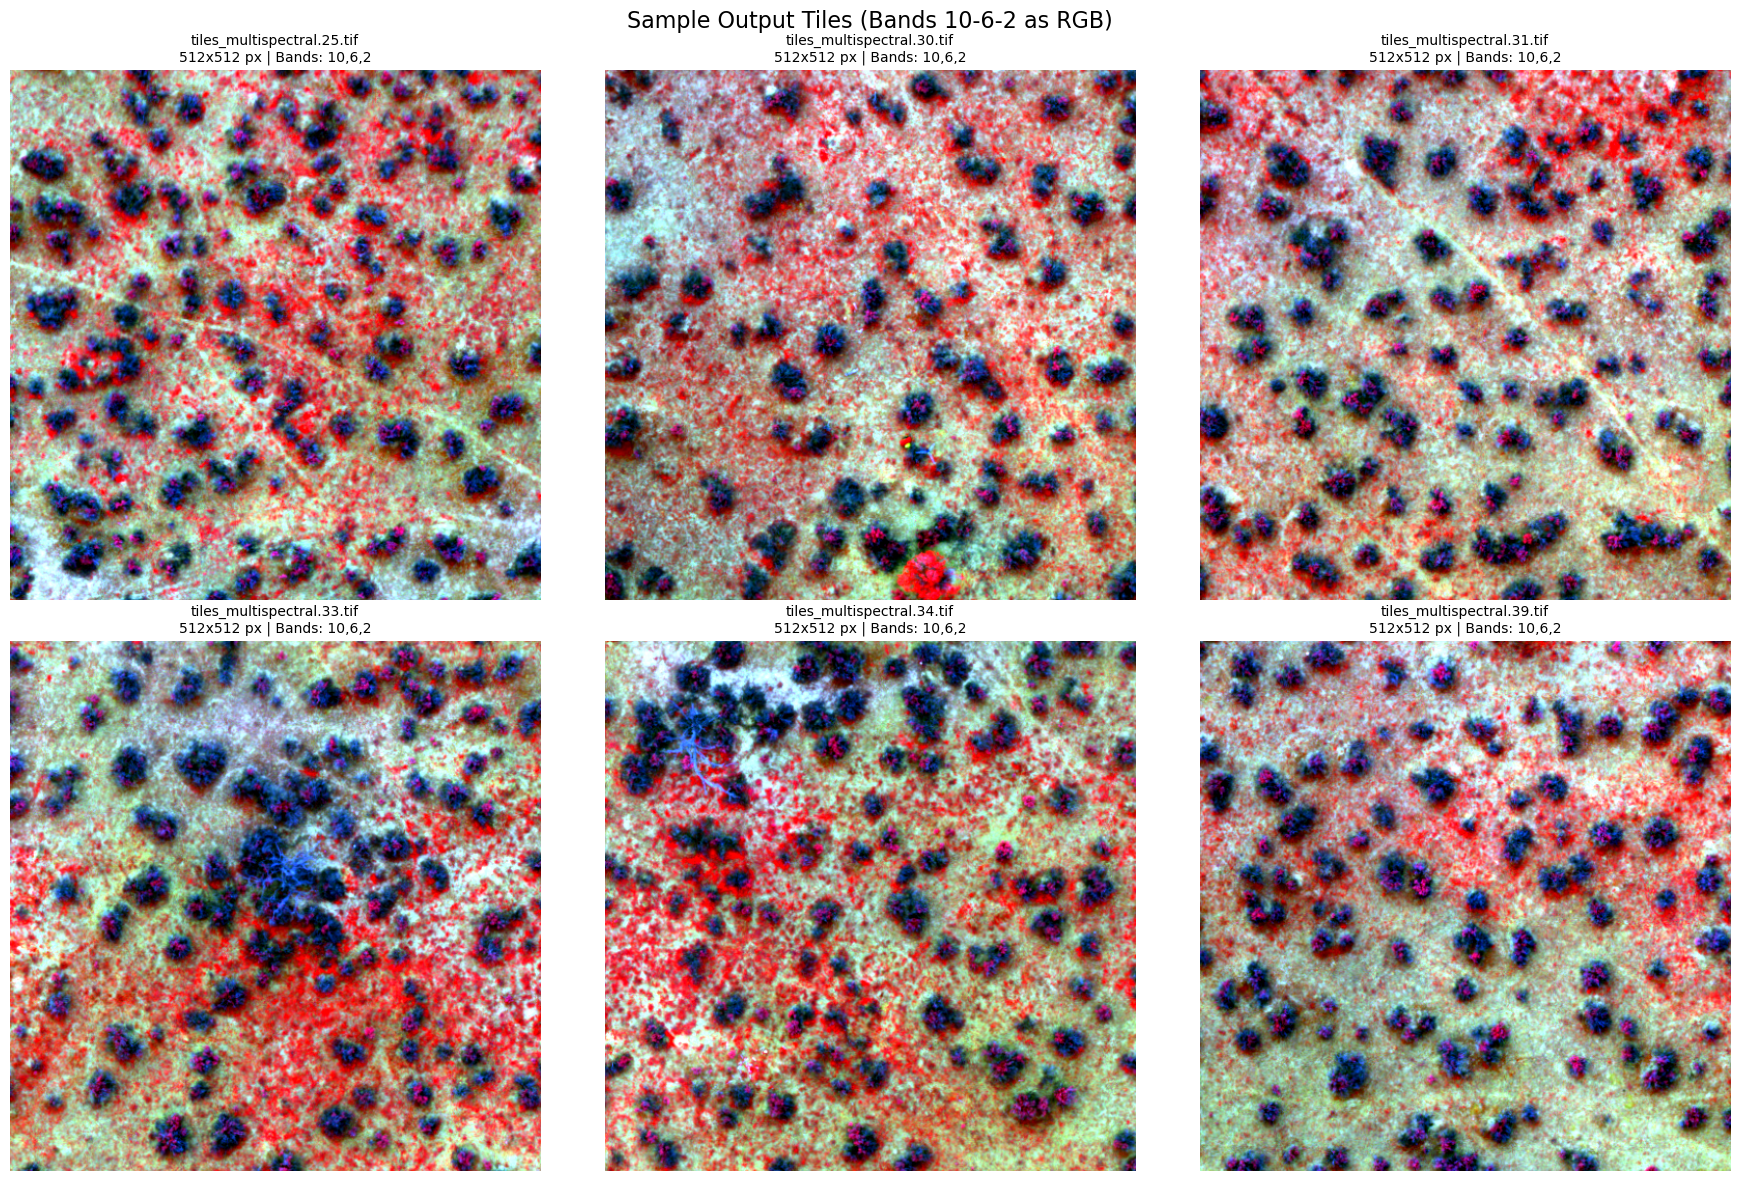

In [ ]:
# Display sample output tiles (Bands 10-6-2 as RGB) using PER-BAND percentile stretch (Option A)
if os.path.exists(output_raster_folder):
    output_tiles = sorted(Path(output_raster_folder).glob("tiles_multispectral.*.tif"))

    if len(output_tiles) > 0:
        print(f"Found {len(output_tiles)} output tiles\n")

        num_samples = min(6, len(output_tiles))
        fig, axes = plt.subplots(2, 3, figsize=(18, 12))
        axes = axes.flatten()

        for idx, tile_path in enumerate(output_tiles[:num_samples]):
            with rasterio.open(tile_path) as src:

                if src.count >= 10:
                    bands = [10, 6, 2]
                    rgb = np.stack([src.read(b).astype(np.float32) for b in bands], axis=-1)

                    nodata_val = src.nodata if src.nodata is not None else -32767

                    # Valid pixels: all three bands not nodata and > 0
                    valid = np.all((rgb != nodata_val) & (rgb > 0), axis=-1)

                    print(f"Tile {idx+1} ({tile_path.name}):")
                    print(f"  Data type: {src.dtypes[0]}")
                    print(f"  NoData value: {nodata_val}")
                    print(f"  Total pixels: {rgb.shape[0] * rgb.shape[1]}")
                    print(f"  Valid pixels: {int(valid.sum())}")

                    rgb_norm = np.zeros_like(rgb, dtype=np.float32)

                    if valid.any():
                        # PER-BAND robust stretch (2–98%) -> QGIS-like behaviour
                        for c in range(3):
                            v = rgb[..., c][valid]
                            p2, p98 = np.percentile(v, [2, 98])
                            print(f"  Band {bands[c]} stretch: P2={p2:.6f}, P98={p98:.6f}")
                            rgb_norm[..., c] = (rgb[..., c] - p2) / (p98 - p2 + 1e-8)

                        rgb_norm = np.clip(rgb_norm, 0, 1)
                        rgb_norm[~valid] = 0  # paint nodata/invalid black
                    else:
                        print("  ❌ WARNING: No valid data! All pixels are NoData or zero.")

                    axes[idx].imshow(rgb_norm)
                    print()

                elif src.count >= 3:
                    # Fallback to standard RGB if fewer than 10 bands (also per-band percentile stretch)
                    bands = [1, 2, 3]
                    rgb = np.stack([src.read(b).astype(np.float32) for b in bands], axis=-1)

                    nodata_val = src.nodata if src.nodata is not None else -32767
                    valid = np.all((rgb != nodata_val) & (rgb > 0), axis=-1)

                    rgb_norm = np.zeros_like(rgb, dtype=np.float32)
                    if valid.any():
                        for c in range(3):
                            v = rgb[..., c][valid]
                            p2, p98 = np.percentile(v, [2, 98])
                            rgb_norm[..., c] = (rgb[..., c] - p2) / (p98 - p2 + 1e-8)
                        rgb_norm = np.clip(rgb_norm, 0, 1)
                        rgb_norm[~valid] = 0

                    axes[idx].imshow(rgb_norm)

                else:
                    axes[idx].imshow(src.read(1), cmap="gray")

                axes[idx].set_title(
                    f"{tile_path.name}\n{src.width}x{src.height} px | Bands: 10,6,2",
                    fontsize=10
                )
                axes[idx].axis("off")

        for j in range(num_samples, 6):
            axes[j].axis("off")

        plt.suptitle("Sample output tiles (Bands 10-6-2 as RGB)", fontsize=16, y=0.98)
        plt.tight_layout()
        plt.show()
    else:
        print("No output tiles found")
else:
    print("Output folder does not exist")


In [9]:
# Summary of processing
if os.path.exists(output_raster_folder):
    output_tiles = list(Path(output_raster_folder).glob("tiles_multispectral.*.tif"))
    
    print("="*60)
    print("PROCESSING SUMMARY")
    print("="*60)
    print(f"Input raster: {os.path.basename(input_raster_path)}")
    print(f"Grid shapefile: {os.path.basename(grid_shapefile_path)}")
    print(f"Output folder: {output_raster_folder}")
    print(f"\nTiles created: {len(output_tiles)}")
    
    if len(output_tiles) > 0:
        # Check tile dimensions
        sample_tile = output_tiles[0]
        with rasterio.open(sample_tile) as src:
            print(f"Tile dimensions: {src.width} x {src.height} pixels")
            print(f"Tile resolution: {src.res[0]:.4f} m/pixel")
            print(f"Bands per tile: {src.count}")
            
            # Calculate total size
            total_size = sum(f.stat().st_size for f in output_tiles) / (1024**2)  # MB
            print(f"Total output size: {total_size:.2f} MB")
    
    print("="*60)
else:
    print("No output folder found")

PROCESSING SUMMARY
Input raster: 20220517_SASMDD0011_dual_ortho_06.tif
Grid shapefile: grid_annotation_3072.shp
Output folder: /data/calperumResearch/site2_1_DD0011/imagery/inputs/predictors/tiles_3072/raw

Tiles created: 18
Tile dimensions: 512 x 512 pixels
Tile resolution: 0.0600 m/pixel
Bands per tile: 10
Total output size: 180.06 MB
